# 01 — Cellule crayon de REP : k∞ et spectre neutronique

**Objectif** : modéliser un crayon combustible de réacteur à eau pressurisée (REP) dans son environnement
d'eau, calculer son **facteur de multiplication infini k∞** et tracer le **spectre en énergie du flux neutronique**.

**Ce qu'on modélise**

| Élément | Choix | Pourquoi |
|---|---|---|
| Combustible | UO₂ enrichi à 4 % en U-235, 10,4 g/cm³, 900 K | Enrichissement typique d'un REP actuel ; 900 K ≈ température moyenne de la pastille |
| Jeu | Hélium, 84 µm | Gaz de remplissage entre pastille et gaine |
| Gaine | Zircaloy-4, 600 K | Alliage de zirconium, très peu absorbant |
| Modérateur | Eau légère borée à 1000 ppm, 580 K, 155 bar | Conditions du circuit primaire en fonctionnement ; bore = poison soluble de contrôle |
| Bords | Réfléchissants sur les 6 faces | Équivaut à un réseau **infini** de crayons identiques |

**Plan** : matériaux → géométrie → paramètres Monte-Carlo → tallies (grandeurs à mesurer) → calcul → analyse.

## 0. Un peu de physique : que représente k∞ ?

Dans un réacteur, chaque fission produit en moyenne ν ≈ 2,4 neutrons. Ces neutrons naissent rapides (~2 MeV),
sont ralentis par les chocs sur l'hydrogène de l'eau, puis sont soit absorbés (par l'U-238, l'eau, le bore,
la gaine…), soit provoquent une nouvelle fission. On définit le **facteur de multiplication** :

$$k = \frac{\text{neutrons produits par fission à la génération } n+1}{\text{neutrons de la génération } n}$$

- $k = 1$ : réaction en chaîne stable (**critique**) ; $k > 1$ : surcritique ; $k < 1$ : sous-critique.
- **k∞** (k-infini) est la valeur pour un milieu **sans fuites**. Comme nos bords sont réfléchissants,
  aucun neutron ne sort : on obtient k∞ = (production par fission) / (absorption).
- On l'exprime souvent par la **formule des quatre facteurs** : $k_\infty = \varepsilon \, p \, f \, \eta$
  (fissions rapides, probabilité d'échapper aux résonances de l'U-238, facteur d'utilisation thermique,
  facteur de reproduction). Les études paramétriques du notebook 02 joueront sur ces facteurs.

Un cœur réel a des fuites, donc $k_{\text{eff}} < k_\infty$ : une cellule crayon doit avoir un k∞ nettement
supérieur à 1 pour qu'un cœur entier puisse être critique.

## 1. Préparation de l'environnement

Les fonctions qui créent les matériaux et la géométrie sont dans `src/` pour être réutilisées dans les
notebooks suivants. Les fichiers produits par OpenMC (XML d'entrée, HDF5 de sortie) sont écrits dans
`runs/01_pin_cell/`, un dossier ignoré par git : ils sont régénérés à chaque exécution.

In [1]:
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc

RACINE = Path.cwd().parent            # ce notebook est dans notebooks/
sys.path.insert(0, str(RACINE))
from src.style import appliquer_style, COULEURS
appliquer_style()
from src.materiaux import combustible_uo2, helium_jeu, zircaloy4, eau_boree
from src.geometrie import cellule_crayon, PAS, HAUTEUR

# Le module Python `openmc` lance l'exécutable C++ `openmc`, installé à côté de l'interpréteur
# Python de l'environnement conda : on s'assure qu'il est dans le PATH.
os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]

# OpenMC trouve les sections efficaces grâce à cette variable (voir README).
# Si elle n'est pas définie, on prend l'emplacement par défaut du README.
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "01_pin_cell"
DOSSIER_RESULTATS = RACINE / "results" / "01_pin_cell"   # figures et tableaux de ce notebook
DOSSIER_CALCUL.mkdir(parents=True, exist_ok=True)
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)

print("OpenMC", openmc.__version__)
print("Bibliothèque :", Path(os.environ["OPENMC_CROSS_SECTIONS"]).parent.name)

OpenMC 0.16.0
Bibliothèque : endfb-viii.0-hdf5


## 2. Matériaux

Chaque matériau est défini par sa composition, sa densité et sa **température**. La température compte :
l'agitation thermique des noyaux élargit les résonances d'absorption (**effet Doppler**), et la densité de
l'eau chute fortement quand elle chauffe (0,71 g/cm³ à 580 K et 155 bar contre 1,0 g/cm³ à 20 °C).

- `add_element("U", enrichment=4.0)` répartit automatiquement l'uranium entre U-234, U-235, U-236 et U-238.
- L'eau borée inclut la loi de diffusion **S(α,β)** de l'hydrogène lié dans H₂O : à basse énergie
  (< ~4 eV), un neutron ne voit pas un proton libre mais une molécule qui vibre et tourne, ce qui modifie
  fortement la thermalisation.

In [2]:
combustible = combustible_uo2(enrichissement=4.0)
helium = helium_jeu()
gaine = zircaloy4()
eau = eau_boree(bore_ppm=1000)

materiaux = openmc.Materials([combustible, helium, gaine, eau])

pd.DataFrame(
    {
        "densité (g/cm³)": [m.get_mass_density() for m in materiaux],
        "température (K)": [m.temperature for m in materiaux],
    },
    index=[m.name for m in materiaux],
).round(4)

,densité (g/cm³),température (K)
UO2 4 %,10.4000,900.0
Hélium,0.0015,600.0
Zircaloy-4,6.5600,600.0
Eau borée 1000 ppm,0.7126,580.0


Composition isotopique du combustible, en densités atomiques (atomes par barn·cm, soit 10²⁴ atomes/cm³).
On voit que l'U-238 reste très majoritaire : c'est lui qui capture une partie des neutrons pendant leur
ralentissement, dans ses résonances.

In [3]:
densites = combustible.get_nuclide_atom_densities()
pd.Series(densites, name="atomes/(b·cm)").map("{:.4e}".format).to_frame()

,atomes/(b·cm)
U234,8.3973e-06
U235,9.3950e-04
U238,2.2251e-02
U236,4.3033e-06
O16,4.6295e-02
O17,1.7588e-05
O18,9.2830e-05


## 3. Géométrie

OpenMC utilise la **géométrie constructive des solides** (CSG) : on définit des **surfaces** (ici trois cylindres
coaxiaux et une boîte), puis des **cellules** = régions délimitées par ces surfaces et remplies d'un matériau.
Dimensions de type Westinghouse 17×17 : pastille de rayon 0,4096 cm, gaine 0,418 → 0,475 cm, pas du réseau 1,26 cm.

In [4]:
geometrie, cellules = cellule_crayon(combustible, helium, gaine, eau)

for nom, c in cellules.items():
    print(f"{nom:12s} volume = {c.volume:7.4f} cm³   ({c.fill.name})")

rapport = cellules["moderateur"].volume / cellules["combustible"].volume
print(f"\nRapport de modération V_eau / V_combustible = {rapport:.2f}")

combustible  volume =  5.2707 cm³   (UO2 4 %)
jeu          volume =  0.2184 cm³   (Hélium)
gaine        volume =  1.5991 cm³   (Zircaloy-4)
moderateur   volume =  8.7878 cm³   (Eau borée 1000 ppm)

Rapport de modération V_eau / V_combustible = 1.67


Le **rapport de modération** (≈ 1,7 ici) est un paramètre de conception clé : plus il y a d'eau par rapport au
combustible, mieux les neutrons sont ralentis… mais plus l'eau (et son bore) en capture. Les REP sont
volontairement **sous-modérés**, ce qui garantit un coefficient de température du modérateur négatif
(étudié dans le notebook 02).

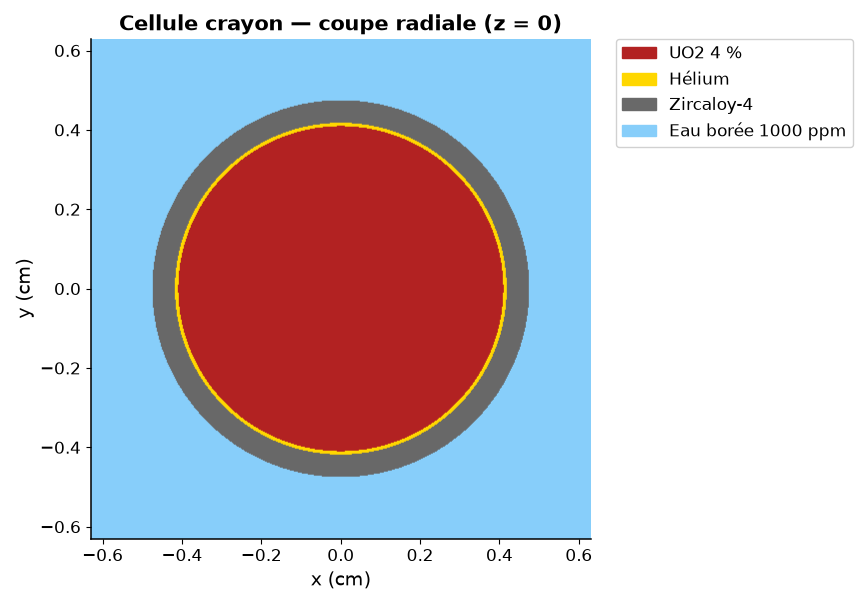

In [5]:
couleurs = {combustible: "firebrick", helium: "gold", gaine: "dimgray", eau: "lightskyblue"}
ax = geometrie.root_universe.plot(
    width=(PAS, PAS), pixels=(500, 500), color_by="material", colors=couleurs, legend=True
)
ax.set_title("Cellule crayon — coupe radiale (z = 0)")
ax.grid(False)
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.figure.savefig(DOSSIER_RESULTATS / "geometrie.png", bbox_inches="tight")
plt.show()

### Contrôle de la géométrie : chevauchements

En géométrie CSG, c'est à nous de garantir que **chaque point de l'espace appartient à une et une seule
cellule**. Une erreur de signe (`+s` au lieu de `-s`) ou un rayon mal choisi peut créer une zone qui
appartient à deux cellules à la fois (**chevauchement**), ou à aucune. OpenMC ne le détecte pas
forcément pendant le calcul : un neutron qui entre dans une telle zone suit l'une ou l'autre cellule
selon l'ordre de recherche, et le résultat est silencieusement faux.

On vérifie donc la géométrie avant tout calcul :
- **visuellement** : coupe colorée par **cellule** (et non plus par matériau), avec les contours
  (`outline=True`) et les chevauchements affichés en rouge (`show_overlaps=True`) ;
- **numériquement** : `slice_data` renvoie, pour chaque pixel, l'identifiant de la cellule trouvée. Un
  identifiant négatif signale un point sans cellule ou en chevauchement. On impose qu'il n'y en ait aucun.

Ce contrôle ne porte que sur un plan de coupe ; pour une géométrie 3D complexe, il faut le répéter sur
plusieurs plans (et OpenMC propose aussi un mode `geometry_debug` pendant le transport, plus coûteux).

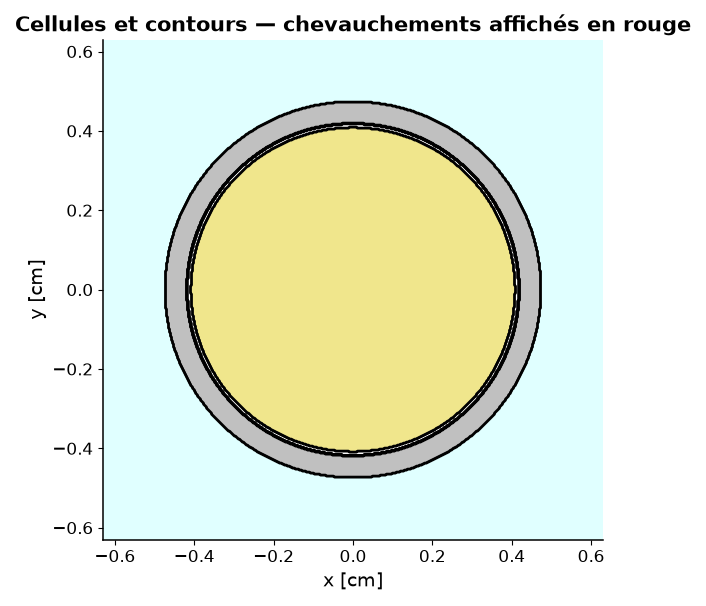

Cellules trouvées sur la coupe : [1, 2, 3, 4]
Pixels sans cellule ou en chevauchement : 0 / 1000000


In [6]:
modele_geometrie = openmc.Model(geometry=geometrie, materials=materiaux)

# Vue colorée par cellule, contours et chevauchements (en rouge).
# Couleurs fixées sans rouge, pour qu'un éventuel chevauchement ressorte sans ambiguïté.
couleurs_cellules = {
    cellules["combustible"]: "khaki", cellules["jeu"]: "white",
    cellules["gaine"]: "silver", cellules["moderateur"]: "lightcyan",
}
ax = modele_geometrie.plot(
    width=(PAS, PAS), pixels=(500, 500), color_by="cell", colors=couleurs_cellules,
    outline=True, show_overlaps=True,
)
ax.set_title("Cellules et contours — chevauchements affichés en rouge")
ax.grid(False)
plt.show()

# Contrôle numérique sur une coupe fine
donnees, _ = modele_geometrie.slice_data(width=(PAS, PAS), pixels=(1000, 1000), show_overlaps=True)
id_cellules = donnees[..., 0]
n_problemes = int((id_cellules < 0).sum())
print(f"Cellules trouvées sur la coupe : {sorted(set(id_cellules.ravel().tolist()))}")
print(f"Pixels sans cellule ou en chevauchement : {n_problemes} / {id_cellules.size}")
assert n_problemes == 0, "Géométrie incorrecte : corriger avant de lancer le calcul"

## 4. Paramètres de la simulation Monte-Carlo

### Le calcul de criticité par itération sur la source

OpenMC suit les neutrons un par un, en tirant au hasard (selon les sections efficaces) la distance jusqu'au
prochain choc, le type de réaction, l'énergie et la direction après le choc. Pour un calcul de k, on procède par
**générations** (appelées *batches* ici) :

1. On place une source initiale arbitraire (ici : uniforme dans le combustible).
2. On suit `particles` neutrons jusqu'à leur disparition et on enregistre les **sites de fission** produits.
3. Ces sites deviennent la source de la génération suivante, et ainsi de suite.

### Cycles inactifs et actifs

Au début, la répartition spatiale des sources dépend de notre choix initial arbitraire et n'est pas encore
la **distribution fondamentale** : les k calculés sont biaisés. On écarte donc les premières générations,
dites **inactives** (rien n'est comptabilisé). Ensuite, les générations **actives** sont moyennées.

Pour vérifier que la source a convergé, on suit l'**entropie de Shannon** de la répartition des sites de
fission sur un maillage : elle doit se stabiliser avant la fin des cycles inactifs.

### Incertitude statistique

Chaque génération active donne une estimation $k_i$. Le résultat est la moyenne, avec un écart-type
$\sigma \approx s / \sqrt{N_\text{actifs}}$ ($s$ : dispersion des $k_i$). Pour diviser l'incertitude par 2, il faut
**4 fois plus** de neutrons : c'est la convergence en $1/\sqrt{N}$ propre au Monte-Carlo.

In [7]:
reglages = openmc.Settings()
reglages.batches = 200          # générations au total
reglages.inactive = 50          # générations écartées (convergence de la source)
reglages.particles = 20_000     # neutrons par génération  -> 150 × 20 000 = 3 millions d'histoires actives

# Source initiale : uniforme dans une boîte englobant la pastille, en ne gardant que les points
# situés dans un matériau fissile.
reglages.source = openmc.IndependentSource(
    space=openmc.stats.Box((-0.41, -0.41, -HAUTEUR / 2), (0.41, 0.41, HAUTEUR / 2)),
    constraints={"fissionable": True},
)

# Sections efficaces interpolées entre les températures tabulées (294, 600, 900 K…)
reglages.temperature = {"method": "interpolation"}

# Maillage pour l'entropie de Shannon (10 × 10 mailles dans le plan, 1 en z)
maillage = openmc.RegularMesh()
maillage.lower_left = (-PAS / 2, -PAS / 2, -HAUTEUR / 2)
maillage.upper_right = (PAS / 2, PAS / 2, HAUTEUR / 2)
maillage.dimension = (10, 10, 1)
reglages.entropy_mesh = maillage

reglages.seed = 1               # graine du générateur aléatoire : résultats reproductibles

## 5. Tallies : ce que l'on mesure

Un **tally** accumule une grandeur pendant la simulation, éventuellement découpée par **filtres**
(cellule, énergie, maille…).

- **Spectre** : le flux $\phi$ dans le combustible et dans le modérateur, découpé en 1000 intervalles
  d'énergie répartis logarithmiquement de 10⁻⁵ eV à 20 MeV. Le flux est estimé par la **longueur de trace** :
  la somme des distances parcourues par les neutrons dans la cellule, divisée par son volume.
- **Bilan** : sur tout le domaine, les taux de production de neutrons par fission ($\nu\Sigma_f\phi$),
  d'absorption ($\Sigma_a\phi$) et des réactions (n,2n) et (n,3n), qui multiplient les neutrons sans fission.
  Sans fuites, k∞ = production / absorption : c'est un contrôle de cohérence indépendant.

In [8]:
filtre_cellules = openmc.CellFilter([cellules["combustible"], cellules["moderateur"]])
bornes_energie = np.logspace(np.log10(1e-5), np.log10(20e6), 1001)   # eV
filtre_energie = openmc.EnergyFilter(bornes_energie)

tally_spectre = openmc.Tally(name="spectre")
tally_spectre.filters = [filtre_cellules, filtre_energie]
tally_spectre.scores = ["flux"]

tally_bilan = openmc.Tally(name="bilan")
tally_bilan.scores = ["nu-fission", "absorption", "(n,2n)", "(n,3n)"]

tallies = openmc.Tallies([tally_spectre, tally_bilan])

## 6. Lancement du calcul

`Model` regroupe matériaux, géométrie, réglages et tallies ; `run()` écrit les fichiers XML d'entrée, lance
le solveur C++ (en parallèle sur tous les cœurs du processeur) et renvoie le chemin du fichier de résultats
**statepoint** (HDF5). Durée : environ deux minutes.

In [9]:
modele = openmc.Model(geometry=geometrie, materials=materiaux, settings=reglages, tallies=tallies)

# calculer_k (src/calcul.py) lance modele.run() et réutilise le résultat d'un calcul précédent
# si les entrées sont strictement identiques : relancer le notebook ne refait pas le calcul.
from src.calcul import calculer_k

resultat = calculer_k(modele, DOSSIER_CALCUL)
fichier_resultats = resultat["statepoint"]
if resultat["reutilise"]:
    print("Résultat d'un calcul précédent réutilisé (entrées identiques).")
else:
    n_histoires = reglages.particles * reglages.batches
    print(f"Calcul terminé en {resultat['duree']:.0f} s — "
          f"{n_histoires / resultat['duree']:,.0f} neutrons/s".replace(",", " "))

Résultat d'un calcul précédent réutilisé (entrées identiques).


## 7. Résultats

### 7.1 Le facteur de multiplication infini

OpenMC calcule k avec trois **estimateurs** différents, qui comptent les neutrons produits à des moments
différents de leur vie : à chaque **collision**, à chaque **absorption**, ou le long de chaque **trace**
(trajet entre deux chocs). Ils mesurent la même grandeur mais avec des bruits statistiques partiellement
indépendants : OpenMC les combine donc pour réduire l'incertitude. `sp.keff` est cette estimation combinée.
On exprime aussi la **réactivité** $\rho = (k-1)/k$, en pcm (1 pcm = 10⁻⁵).

In [10]:
with openmc.StatePoint(fichier_resultats) as sp:
    k_inf = sp.keff                               # nombre avec incertitude (ufloat)
    estimateurs = sp.global_tallies[:3]           # collision, absorption, longueur de trace
    k_generations = np.array(sp.k_generation)     # k de chaque génération
    entropie = np.array(sp.entropy)
    spectre = sp.get_tally(name="spectre").get_reshaped_data(value="mean").squeeze()
    spectre_sd = sp.get_tally(name="spectre").get_reshaped_data(value="std_dev").squeeze()
    bilan = sp.get_tally(name="bilan")
    nu_fission, absorption, n2n, n3n = bilan.get_values(
        scores=["nu-fission", "absorption", "(n,2n)", "(n,3n)"]
    ).ravel()

for nom, moyenne, ecart in zip(estimateurs["name"], estimateurs["mean"], estimateurs["std_dev"]):
    print(f"  {nom.decode():15s} k = {moyenne:.5f} ± {ecart:.5f}")
print()

k, sigma = k_inf.nominal_value, k_inf.std_dev
rho = (k - 1) / k * 1e5
print(f"k∞ combiné = {k:.5f} ± {sigma:.5f}   (1σ, soit ± {sigma * 1e5:.0f} pcm)")
print(f"Intervalle de confiance à 95 % : [{k - 1.96 * sigma:.5f} ; {k + 1.96 * sigma:.5f}]")
print(f"Réactivité ρ = {rho:,.0f} pcm".replace(",", " "))

# Bilan neutronique : une (n,2n) ajoute 1 neutron net, une (n,3n) en ajoute 2
k_fission_seule = nu_fission / absorption
k_bilan = (nu_fission + n2n + 2 * n3n) / absorption
print(f"\nContrôle par bilan :")
print(f"  fission seule        νΣf / Σa                = {k_fission_seule:.5f}")
print(f"  bilan complet  (νΣf + n2n + 2·n3n) / Σa      = {k_bilan:.5f}")
print(f"  contribution des (n,xn) : {(k_bilan - k_fission_seule) * 1e5:.0f} pcm")

  k-collision     k = 1.26405 ± 0.00077
  k-absorption    k = 1.26470 ± 0.00062
  k-tracklength   k = 1.26456 ± 0.00088

k∞ combiné = 1.26468 ± 0.00055   (1σ, soit ± 55 pcm)
Intervalle de confiance à 95 % : [1.26360 ; 1.26575]
Réactivité ρ = 20 928 pcm

Contrôle par bilan :
  fission seule        νΣf / Σa                = 1.26260
  bilan complet  (νΣf + n2n + 2·n3n) / Σa      = 1.26418
  contribution des (n,xn) : 158 pcm


**Interprétation.** k∞ est nettement supérieur à 1 : ce réseau infini de crayons est fortement surcritique. C'est
normal et nécessaire : un cœur réel perd des neutrons par les fuites aux bords, contient des grappes de
commande et des absorbants, et son combustible s'appauvrit en U-235 au fil du cycle. La réserve de
réactivité est compensée en début de cycle par le **bore** dissous, dont la concentration est réduite
progressivement (notebook 02 : effet de la concentration en bore).

**Contrôle par bilan.** Le rapport νΣf/Σa seul sous-estime k∞ d'environ 200 pcm, soit près de 4σ : l'écart
n'est donc pas du bruit statistique. Il manque les neutrons créés par les réactions (n,2n) et (n,3n),
principalement sur l'U-238 au-dessus de ~6 MeV. Ces réactions apportent environ 160 pcm ; une fois
comptées, le bilan production/absorption redonne k∞ à environ 50 pcm près, c'est-à-dire à 1σ.
Un bon contrôle de cohérence doit inclure toute la physique.

### 7.2 Convergence : cycles inactifs et actifs

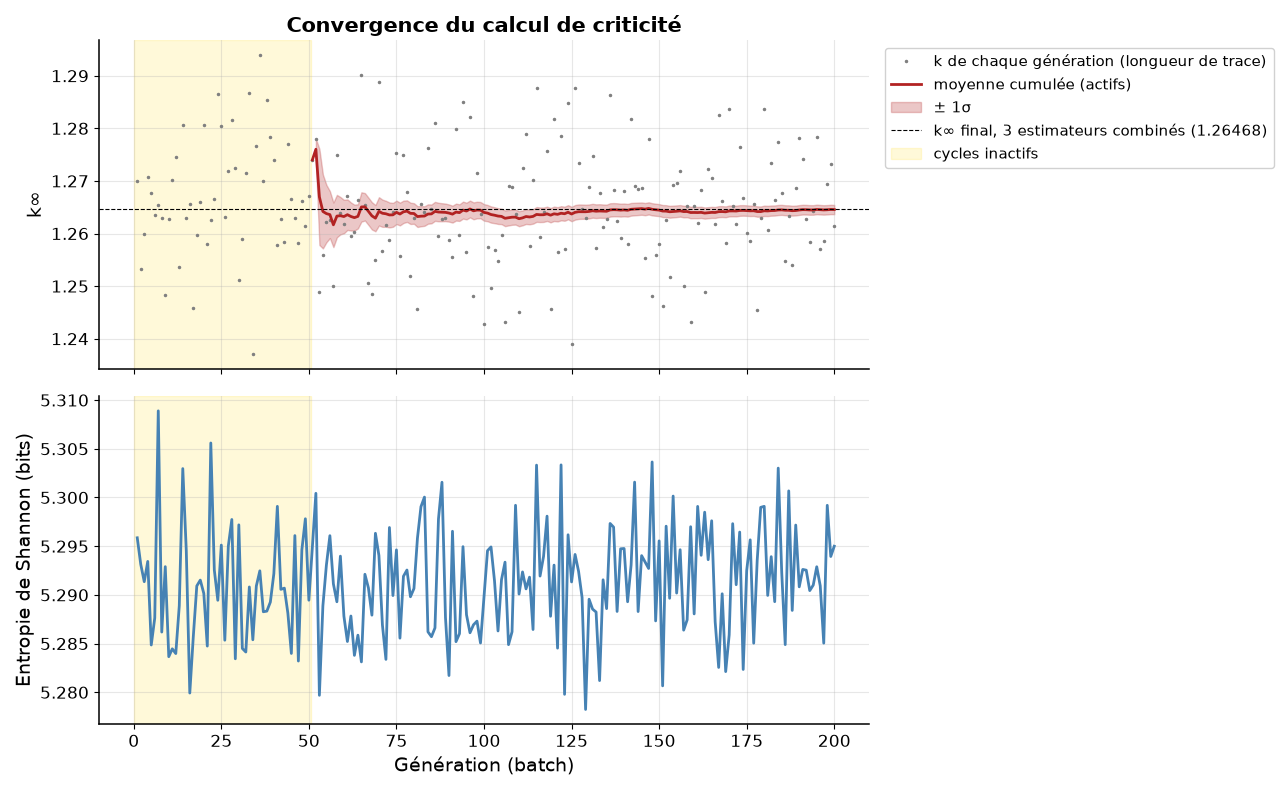

Dispersion d'une génération         s = 1081 pcm
Moyenne des 150 générations actives   : 1.26456 ± 0.00088  (longueur de trace seule)
k∞ combiné (3 estimateurs)          : 1.26468 ± 0.00055
Moyenne des 50 générations inactives : 1.26700 ± 0.00158
Autocorrélation entre générations successives : -0.19
Entropie : de 5.278 à 5.309 bits (maximum possible log2(100) = 6.64)


In [11]:
n_inactifs = reglages.inactive
generations = np.arange(1, len(k_generations) + 1)

# Moyenne cumulée des cycles actifs et son incertitude, génération après génération
actifs = k_generations[n_inactifs:]
n = np.arange(1, len(actifs) + 1)
moyenne_cumulee = np.cumsum(actifs) / n
ecart_type = np.array([actifs[:i].std(ddof=1) / np.sqrt(i) if i > 1 else np.nan for i in n])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax1.plot(generations, k_generations, ".", ms=3, color="gray", label="k de chaque génération (longueur de trace)")
ax1.plot(generations[n_inactifs:], moyenne_cumulee, color="firebrick", label="moyenne cumulée (actifs)")
ax1.fill_between(generations[n_inactifs:], moyenne_cumulee - ecart_type, moyenne_cumulee + ecart_type,
                 color="firebrick", alpha=0.25, label="± 1σ")
ax1.axhline(k, color="k", ls="--", lw=0.8, label=f"k∞ final, 3 estimateurs combinés ({k:.5f})")
ax1.axvspan(0, n_inactifs + 0.5, color="gold", alpha=0.15, label="cycles inactifs")
ax1.set_ylabel("k∞")
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=11)
ax1.set_title("Convergence du calcul de criticité")

ax2.plot(np.arange(1, len(entropie) + 1), entropie, color="steelblue")
ax2.axvspan(0, n_inactifs + 0.5, color="gold", alpha=0.15)
ax2.set_xlabel("Génération (batch)")
ax2.set_ylabel("Entropie de Shannon (bits)")

fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "convergence.png", bbox_inches="tight")
plt.show()

inactifs = k_generations[:n_inactifs]
ecarts = actifs - actifs.mean()
autocorrelation = np.sum(ecarts[1:] * ecarts[:-1]) / np.sum(ecarts**2)
print(f"Dispersion d'une génération         s = {actifs.std(ddof=1) * 1e5:.0f} pcm")
print(f"Moyenne des {len(actifs)} générations actives   : {actifs.mean():.5f} ± {ecart_type[-1]:.5f}  (longueur de trace seule)")
print(f"k∞ combiné (3 estimateurs)          : {k:.5f} ± {sigma:.5f}")
print(f"Moyenne des {n_inactifs} générations inactives : {inactifs.mean():.5f} ± {inactifs.std(ddof=1) / np.sqrt(n_inactifs):.5f}")
print(f"Autocorrélation entre générations successives : {autocorrelation:+.2f}")
print(f"Entropie : de {entropie.min():.3f} à {entropie.max():.3f} bits (maximum possible log2(100) = {np.log2(100):.2f})")

**Lecture du graphe.**

- **Points gris** : chaque point est le k d'une seule génération de 20 000 neutrons, estimé par la longueur
  de trace. Ils se dispersent avec un écart-type d'environ 1 100 pcm : c'est le bruit statistique d'une
  génération. La **moyenne cumulée** des générations actives (en rouge) se stabilise, et sa bande
  d'incertitude se resserre en $1/\sqrt{N}$ : 1 100 pcm / √150 ≈ 90 pcm à la fin.
- **Pourquoi la courbe rouge ne finit pas exactement sur les tirets noirs ?** La courbe rouge n'utilise
  qu'**un seul** estimateur (longueur de trace : 1,26456 ± 0,00088), alors que le k∞ de la section 7.1 combine
  les trois estimateurs (1,26468 ± 0,00055). Les deux valeurs sont compatibles (12 pcm d'écart, bien moins
  que les incertitudes), et la combinaison réduit l'incertitude de 88 à 55 pcm.
- **Entropie de Shannon** (en bas) : elle est **stable dès la première génération** et ne fait que fluctuer
  entre 5,28 et 5,31 bits (l'échelle verticale grossit énormément ce bruit). Elle reste sous le maximum
  théorique de 6,64 bits, qui correspondrait à des sources réparties uniformément sur les 100 mailles : ici,
  les fissions n'ont lieu que dans les mailles qui recouvrent la pastille. De même, la moyenne des
  générations inactives (1,2670 ± 0,0016) est compatible avec celle des actives (écart d'environ 1,3σ).
  Conclusion : dans une cellule crayon, une source uniforme dans la pastille est déjà quasiment la
  distribution fondamentale, et les 50 cycles inactifs sont ici une marge de sécurité. Pour un assemblage
  ou un cœur, la source initiale est loin de la distribution fondamentale et l'entropie met de nombreuses
  générations à se stabiliser : c'est là que le choix du nombre de cycles inactifs devient critique (notebook 03).

*Subtilité : la corrélation entre générations.* La source d'une génération est issue de la précédente, donc
dans un grand système les k successifs sont **positivement corrélés** : la formule $s/\sqrt{N}$, qui suppose
des générations indépendantes, **sous-estime** alors l'incertitude réelle. On peut le vérifier en mesurant
l'autocorrélation entre générations successives : ici elle vaut environ −0,2, elle n'est donc pas positive.
Dans une cellule crayon, il n'y a pas de sous-estimation à craindre. Ce sera à surveiller pour l'assemblage.

### 7.3 Spectre en énergie du flux

On trace le flux **par unité de léthargie**, $E\,\phi(E)$, sur une échelle logarithmique en énergie.
La léthargie $u = \ln(E_0/E)$ est la variable naturelle du ralentissement : à chaque choc élastique sur
l'hydrogène, un neutron perd en moyenne une fraction constante de son énergie, donc parcourt une distance
constante en léthargie. Dans cette représentation, un flux en $1/E$ (ralentissement pur) apparaît plat.

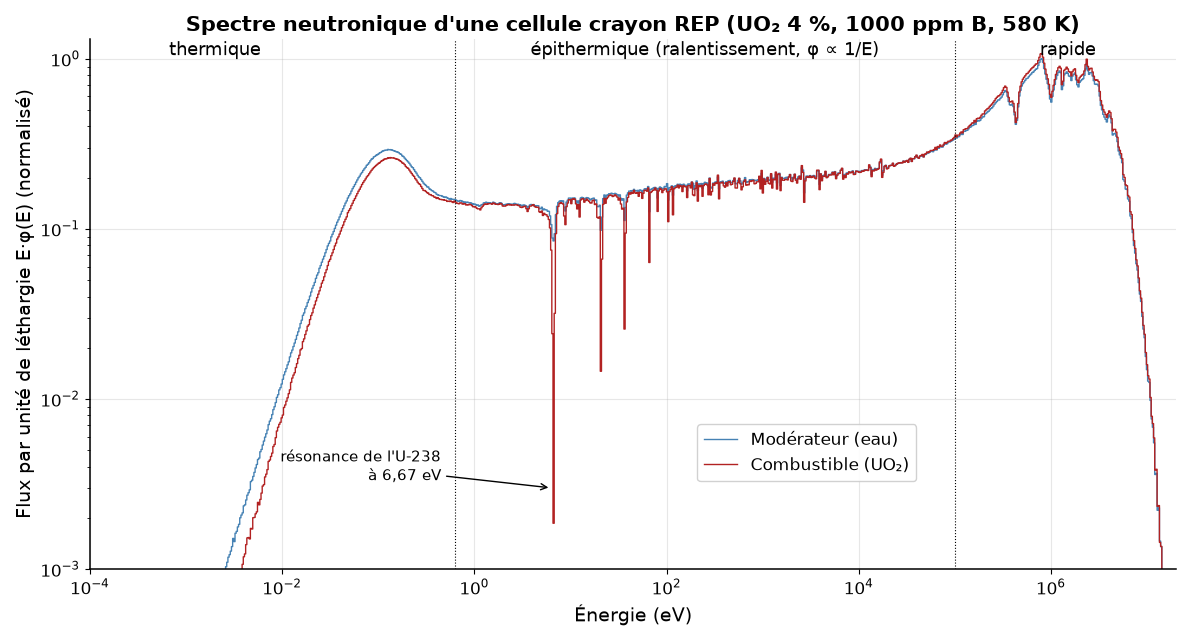

In [12]:
E_bas, E_haut = bornes_energie[:-1], bornes_energie[1:]
E_milieu = np.sqrt(E_bas * E_haut)
d_lethargie = np.log(E_haut / E_bas)

zones = {"combustible": 0, "moderateur": 1}     # ordre du CellFilter
flux_lethargie = {}
for nom, i in zones.items():
    # flux moyen dans la cellule (par neutron source), divisé par la largeur en léthargie
    flux_lethargie[nom] = spectre[i] / cellules[nom].volume / d_lethargie

normalisation = flux_lethargie["moderateur"].max()

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.step(E_milieu, flux_lethargie["moderateur"] / normalisation, where="mid", lw=1,
        color="steelblue", label="Modérateur (eau)")
ax.step(E_milieu, flux_lethargie["combustible"] / normalisation, where="mid", lw=1,
        color="firebrick", label="Combustible (UO₂)")

# Domaines d'énergie
for e in (0.625, 1e5):
    ax.axvline(e, color="k", ls=":", lw=0.8)
ax.text(2e-3, 1.05, "thermique", ha="center")
ax.text(2.5e2, 1.05, "épithermique (ralentissement, φ ∝ 1/E)", ha="center")
ax.text(1.5e6, 1.05, "rapide", ha="center")
ax.annotate("résonance de l'U-238\nà 6,67 eV", xy=(6.3, 0.003), xytext=(0.45, 0.004),
            ha="right", va="center",
            arrowprops=dict(arrowstyle="->"), fontsize=11)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-4, 2e7)
ax.set_ylim(1e-3, 1.3)
ax.set_xlabel("Énergie (eV)")
ax.set_ylabel("Flux par unité de léthargie E·φ(E) (normalisé)")
ax.set_title("Spectre neutronique d'une cellule crayon REP (UO₂ 4 %, 1000 ppm B, 580 K)")
ax.legend(loc="center", bbox_to_anchor=(0.66, 0.22))
ax.grid(which="major", alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "spectre_flux.png", bbox_inches="tight")
plt.show()

**Lecture du spectre, de droite à gauche (dans le sens du ralentissement).**

1. **Domaine rapide (> 100 keV)** : les neutrons naissent de la fission avec un spectre centré vers 1–2 MeV.
   Les creux vers 0,4 et 1 MeV sont des résonances de diffusion de l'**oxygène-16**, présent dans l'eau et dans l'UO₂.
2. **Domaine épithermique** : les neutrons ralentissent par chocs sur l'hydrogène ; le flux suit $1/E$, d'où
   le plateau. Les **creux** sont les grandes **résonances de capture de l'U-238** (6,67 eV, 20,9 eV, 36,7 eV…) :
   à ces énergies, les neutrons sont absorbés dès qu'ils entrent dans le combustible. Le creux est bien
   plus profond dans le combustible que dans l'eau : c'est l'**autoprotection** (le combustible se « cache »
   derrière sa propre surface). La probabilité d'échapper à ces résonances est le facteur $p$ de la formule
   des quatre facteurs.
3. **Domaine thermique (< 0,625 eV)** : les neutrons sont en équilibre avec l'agitation thermique de l'eau à
   580 K (kT ≈ 0,05 eV) ; on retrouve une bosse de type maxwellien, légèrement **durcie** (décalée vers les hautes
   énergies) car les neutrons les plus lents sont absorbés en priorité (absorption en $1/v$).

Le flux thermique est plus faible dans le combustible que dans l'eau : les neutrons thermiques sont produits
dans l'eau (où ils ralentissent) et absorbés dans le combustible. On le quantifie ci-dessous par le
**facteur de désavantage** $\bar\phi_\text{th,mod} / \bar\phi_\text{th,comb}$.

In [13]:
thermique = E_haut <= 0.625
phi = {nom: spectre[i] / cellules[nom].volume for nom, i in zones.items()}   # flux moyen par groupe

for nom in zones:
    fraction = phi[nom][thermique].sum() / phi[nom].sum()
    print(f"Part du flux thermique (< 0,625 eV) dans {nom:12s}: {fraction:6.1%}")

desavantage = phi["moderateur"][thermique].sum() / phi["combustible"][thermique].sum()
print(f"\nFacteur de désavantage thermique φ_th(eau) / φ_th(UO₂) = {desavantage:.3f}")

Part du flux thermique (< 0,625 eV) dans combustible :  10.6%
Part du flux thermique (< 0,625 eV) dans moderateur  :  12.2%

Facteur de désavantage thermique φ_th(eau) / φ_th(UO₂) = 1.145


## 8. Sauvegarde des résultats

Les fichiers HDF5 d'OpenMC ne sont pas versionnés ; on exporte les grandeurs principales en CSV dans
`results/` pour pouvoir les citer et les comparer dans les notebooks suivants.

In [14]:
resume = pd.DataFrame([{
    "enrichissement_pct": 4.0,
    "bore_ppm": 1000,
    "T_moderateur_K": 580,
    "k_inf": round(k, 5),
    "sigma_k": round(sigma, 5),
    "reactivite_pcm": round(rho),
    "facteur_desavantage": round(desavantage, 4),
    "particules": reglages.particles,
    "batches": reglages.batches,
    "inactifs": reglages.inactive,
}])
resume.to_csv(DOSSIER_RESULTATS / "resume.csv", index=False)
resume.T.rename(columns={0: "valeur"})

,valeur
enrichissement_pct,4.00000
bore_ppm,1000.00000
T_moderateur_K,580.00000
k_inf,1.26468
sigma_k,0.00055
reactivite_pcm,20928.00000
facteur_desavantage,1.14490
particules,20000.00000
batches,200.00000
inactifs,50.00000


## 9. Bilan

- On a construit un modèle de cellule crayon REP complet (UO₂ 4 %, gaine Zircaloy-4, eau borée en conditions de
  fonctionnement, réseau infini) et calculé **k∞ avec son incertitude statistique**.
- Le calcul de criticité Monte-Carlo repose sur une itération des sources : les cycles inactifs laissent la source
  converger (entropie de Shannon), les cycles actifs fournissent la moyenne et l'incertitude, qui décroît en $1/\sqrt{N}$.
- Le spectre fait apparaître les trois domaines (rapide, ralentissement en $1/E$, thermique), les résonances de
  l'U-238 et l'autoprotection du combustible.
- **Validation** : le même modèle de cellule crayon, appliqué au problème 1 du benchmark **VERA** (CASL, Oak Ridge,
  spécification CASL-U-2012-0131-004) avec les compositions exactes de sa spécification (UO₂ 3,1 %, 1300 ppm de bore,
  combustible de 565 à 1200 K), donne k∞ à **moins de 100 pcm** de la solution de référence publiée (KENO-VI), dans les
  quatre conditions de température testées, alors que les deux calculs n'utilisent pas la même bibliothèque de données
  (ENDF/B-VIII.0 ici, ENDF/B-VII.0 pour la référence).

**Suite** : le notebook 02 fera varier l'enrichissement, la concentration en bore et la température du modérateur
pour calculer des coefficients de réactivité.